# 03 · Who are our customers?
RFM segmentation per person. Recency and monetary value are quintiles (5 = best).
Frequency is 1, 2 or 3+ orders: with ~97% of customers buying once, frequency quintiles
would put almost everyone into the same bucket.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from _common import ACCENT, MUTED, con

db = con()
db.sql("select frequency, count(*) as customers from mart_rfm group by 1 order by 1").df()

,frequency,customers
0,1,92096
1,2,2651
2,3,188
3,4,29
4,5,9
5,6,5
6,7,3
7,9,1
8,16,1


In [2]:
seg = db.sql("""
    select segment,
           count(*) as customers,
           count(*) / sum(count(*)) over () as share_of_customers,
           sum(monetary) / sum(sum(monetary)) over () as share_of_revenue,
           avg(monetary) as avg_revenue_per_customer,
           median(recency_days) as median_recency_days
    from mart_rfm group by 1 order by share_of_revenue desc
""").df()
seg

,segment,customers,share_of_customers,share_of_revenue,avg_revenue_per_customer,median_recency_days
0,Hibernating,41338,0.435215,0.283705,107.993827,284.0
1,Promising high-value,14640,0.154133,0.281957,303.055897,99.5
2,At risk high-value,14001,0.147405,0.275067,309.143415,387.0
3,Recent,22117,0.232852,0.102698,73.066317,98.0
4,Loyal,1652,0.017393,0.031314,298.269558,302.0
5,Champions,1235,0.013002,0.025260,321.841215,93.0


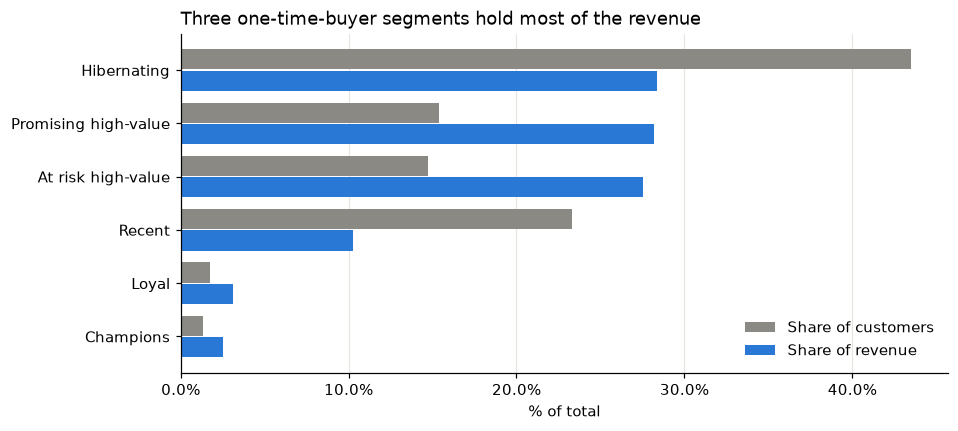

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
y = range(len(seg))[::-1]
ax.barh(
    [i + 0.2 for i in y],
    seg.share_of_customers,
    height=0.38,
    color=MUTED,
    label="Share of customers",
)
ax.barh(
    [i - 0.2 for i in y], seg.share_of_revenue, height=0.38, color=ACCENT, label="Share of revenue"
)
ax.set_yticks(list(y), seg.segment)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("% of total")
ax.set_title("Three one-time-buyer segments hold most of the revenue")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.show()

## What to do with each segment

| Segment | Rule | Action |
|---|---|---|
| Champions | 2+ orders, bought recently | Early access, referral programme |
| Loyal | 2+ orders, not recently | Personalised win-back with category recommendations |
| Promising high-value | 1 order, recent, top-40% spend | Second-purchase offer within the first 30 days |
| Recent | 1 order, recent, lower spend | Onboarding emails, cross-sell cheap add-ons |
| At risk high-value | 1 order, long ago, top-40% spend | Win-back campaign; check whether delivery went wrong |
| Hibernating | everyone else | Low-cost reactivation only |

In [4]:
db.sql("""
    select r.segment,
           avg(o.is_late::int) as late_rate,
           avg(o.review_score) as avg_review_score
    from mart_rfm r
    join fct_orders o using (customer_unique_id)
    where o.is_valid_order
    group by 1 order by late_rate desc
""").df()

,segment,late_rate,avg_review_score
0,Hibernating,0.073106,4.074878
1,Promising high-value,0.068209,4.092172
2,Recent,0.063153,4.223182
3,At risk high-value,0.062935,4.069221
4,Loyal,0.059887,4.099677
5,Champions,0.055175,4.272968


## Findings
- **Two high-value one-time segments** — "Promising high-value" (recent) and "At risk high-value"
  (long ago) — are 30% of customers and bring 56% of revenue, at ~300 BRL per customer.
- Repeat buyers ("Champions" + "Loyal") are only 3% of customers and 6% of revenue.
- Late-delivery rates differ little between segments (5.5–7.3%), so segment membership is not driven
  by delivery experience; the next notebook looks at delivery directly.